# Detecting Phishing and Spam in Student Email
GE2340 *AI: Past, Present & Future* (CityU Hong Kong), Phase 2.

Binary text classifier: **malicious** (phishing/spam, label 1) vs **legitimate** (label 0).

Pipeline (as described in Sections 2-3 of the report):
1. Load `phishing_email.csv` and drop empty and duplicated emails **before** splitting.
2. Stratified train / validation / test split (60/20/20).
3. TF-IDF features (unigrams + bigrams, 15,000 terms, `min_df=5`), fitted on training data only.
4. Baseline: always predict the majority class.
5. Model A: L2-regularised logistic regression. `C` (= inverse of λ) chosen by validation F1,
   decision threshold chosen by validation F2 (recall weighted twice as much as precision).
   Final model refitted on train + validation and evaluated **once** on test.
6. Model B: small neural network (MLP) on the same features, splits and protocol.
7. Test results, McNemar test A vs B. 8. Figures. 9. Top weights. 10. False negatives.
11. Corpus-style check: recover each email's source corpus, per-corpus results, leave-one-corpus-out.

**Running on Google Colab:** upload `phishing_email.csv` from the
[Kaggle dataset](https://www.kaggle.com/datasets/naserabdullahalam/phishing-email-dataset)
into a `data/` folder next to this notebook (or change `DATA_PATH` below). Section 11 also needs the
six per-corpus CSVs from the same download (`CEAS_08.csv`, `Enron.csv`, `Ling.csv`, `Nazario.csv`,
`Nigerian_Fraud.csv`, `SpamAssasin.csv`) in the same folder.

In [1]:
import re
import time
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from scipy.stats import binomtest
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, fbeta_score,
                             precision_recall_curve, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline

DATA_PATH = Path("data/phishing_email.csv")
FIGURES_DIR, RESULTS_DIR = Path("figures"), Path("results")
RANDOM_STATE = 42
C_GRID = [0.01, 0.1, 1, 10, 100, 1000]   # C = inverse regularisation strength (λ ∝ 1/C)
TFIDF_PARAMS = dict(ngram_range=(1, 2), max_features=15_000, min_df=5)

## 1. Load and clean the data

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"{DATA_PATH} not found. Download it from Kaggle (see the first cell).")

raw = pd.read_csv(DATA_PATH)
print("Raw emails:", len(raw))
print(raw["label"].value_counts().rename({1: "malicious", 0: "legitimate"}))

df = raw.copy()
df["text_combined"] = df["text_combined"].fillna("").str.strip()
n_empty = (df["text_combined"] == "").sum()
df = df[df["text_combined"] != ""]
n_dup = df.duplicated(subset="text_combined").sum()
df = df.drop_duplicates(subset="text_combined").reset_index(drop=True)

print(f"\nRemoved {n_empty} empty and {n_dup} duplicated emails")
print("Emails after cleaning:", len(df))
print(df["label"].value_counts().rename({1: "malicious", 0: "legitimate"}))

Raw emails: 82486
label
malicious     42891
legitimate    39595
Name: count, dtype: int64



Removed 1 empty and 408 duplicated emails
Emails after cleaning: 82077
label
malicious     42844
legitimate    39233
Name: count, dtype: int64


## 2. Stratified 60 / 20 / 20 split

In [3]:
X, y = df["text_combined"], df["label"]
X_trval, X_test, y_trval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_trval, y_trval, test_size=0.25, stratify=y_trval, random_state=RANDOM_STATE)  # 0.25 * 0.8 = 0.2

# Sanity checks: no email appears in two partitions, class balance is preserved.
assert not (set(X_train) & set(X_val) or set(X_train) & set(X_test) or set(X_val) & set(X_test))
for name, part in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:5s}: {len(part):6d} emails  ({len(part) / len(y):.0%}),  malicious share = {part.mean():.3f}")

train:  49245 emails  (60%),  malicious share = 0.522
val  :  16416 emails  (20%),  malicious share = 0.522
test :  16416 emails  (20%),  malicious share = 0.522


## 3. Helper: metrics on the malicious class

In [4]:
def evaluate(name, y_true, y_pred):
    """Precision / recall / F1 for the malicious class (label 1) plus confusion-matrix counts."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "model": name,
        "precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "recall": recall_score(y_true, y_pred, pos_label=1),
        "f1": f1_score(y_true, y_pred, pos_label=1),
        "TP": tp, "FN": fn, "FP": fp, "TN": tn,
    }


def f2_threshold(y_true, proba):
    """Decision threshold that maximises F2 (recall weighted twice as much as precision)."""
    prec, rec, thr = precision_recall_curve(y_true, proba, pos_label=1)
    f2 = 5 * prec[:-1] * rec[:-1] / np.maximum(4 * prec[:-1] + rec[:-1], 1e-12)
    return float(thr[np.argmax(f2)])


def show_threshold_effect(y_true, proba, threshold):
    for t in [0.5, threshold]:
        pred = (proba >= t).astype(int)
        print(f"  val @ {t:.4f}: precision={precision_score(y_true, pred):.4f} "
              f"recall={recall_score(y_true, pred):.4f} F2={fbeta_score(y_true, pred, beta=2):.4f}")

## 4. Baseline: always predict the majority class

In [5]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_trval, y_trval)
print("Majority class:", baseline.classes_[np.argmax(baseline.class_prior_)])

Majority class: 1


## 5. Model A: logistic regression with L2 (ridge) regularisation
### 5.1 Choose C on the validation set (F1 at the default 0.5 threshold)
The vectorizer is fitted on the training partition only, then reused for the validation emails.

In [6]:
vectorizer = TfidfVectorizer(**TFIDF_PARAMS)
Xtr_vec = vectorizer.fit_transform(X_train)
Xval_vec = vectorizer.transform(X_val)
print("TF-IDF matrix (train):", Xtr_vec.shape)

# l1_ratio=0 means a pure L2 penalty (scikit-learn >= 1.8 replaced penalty='l2' with l1_ratio).
val_rows = []
for C in C_GRID:
    lr = LogisticRegression(C=C, l1_ratio=0.0, max_iter=1000, random_state=RANDOM_STATE)
    lr.fit(Xtr_vec, y_train)
    val_rows.append({"C": C, "val_f1": f1_score(y_val, lr.predict(Xval_vec)),
                     "train_f1": f1_score(y_train, lr.predict(Xtr_vec))})
val_table = pd.DataFrame(val_rows)
best_C = val_table.loc[val_table["val_f1"].idxmax(), "C"]
print(val_table.to_string(index=False, float_format="%.4f"))
print("\nSelected C =", best_C)

TF-IDF matrix (train): (49245, 15000)


        C  val_f1  train_f1
   0.0100  0.9556    0.9576
   0.1000  0.9724    0.9761
   1.0000  0.9839    0.9899
  10.0000  0.9889    0.9977
 100.0000  0.9891    0.9992
1000.0000  0.9885    0.9999

Selected C = 100.0


### 5.2 Choose the decision threshold on the validation set (maximise F2)
F2 weights recall twice as much as precision, matching our priority: missing a phishing
email is worse than flagging a safe one.

In [7]:
lr_val = LogisticRegression(C=best_C, l1_ratio=0.0, max_iter=1000, random_state=RANDOM_STATE)
lr_val.fit(Xtr_vec, y_train)
val_proba = lr_val.predict_proba(Xval_vec)[:, 1]

threshold_a = f2_threshold(y_val, val_proba)
print(f"Selected threshold = {threshold_a:.4f}")
show_threshold_effect(y_val, val_proba, threshold_a)

Selected threshold = 0.2966
  val @ 0.5000: precision=0.9889 recall=0.9893 F2=0.9892
  val @ 0.2966: precision=0.9821 recall=0.9938 F2=0.9915


### 5.3 Refit on train + validation and evaluate once on the test set
With C and the threshold fixed, the whole pipeline (TF-IDF + logistic regression) is refitted on
train + validation. The test set is used only here.

In [8]:
model_a = Pipeline([
    ("tfidf", TfidfVectorizer(**TFIDF_PARAMS)),
    ("lr", LogisticRegression(C=best_C, l1_ratio=0.0, max_iter=1000, random_state=RANDOM_STATE)),
])
t0 = time.perf_counter()
model_a.fit(X_trval, y_trval)
fit_seconds = {"A": time.perf_counter() - t0}   # includes fitting the TF-IDF vectorizer
print(f"Training time (TF-IDF + LR): {fit_seconds['A']:.1f} s")

test_proba_a = model_a.predict_proba(X_test)[:, 1]

Training time (TF-IDF + LR): 57.1 s


## 6. Model B: small neural network (MLP)
Same TF-IDF features, same splits and the same protocol as model A: train on the training
partition, choose the F2 threshold on validation, refit on train + validation, test once.
Architecture: one hidden layer of 64 ReLU units, Adam optimiser, early stopping
(10% of the fitting data is held out internally to decide when to stop).

In [9]:
MLP_PARAMS = dict(hidden_layer_sizes=(64,), activation="relu", solver="adam",
                  early_stopping=True, random_state=RANDOM_STATE)

mlp_val = MLPClassifier(**MLP_PARAMS).fit(Xtr_vec, y_train)
print("Epochs until early stopping:", mlp_val.n_iter_)
val_proba_b = mlp_val.predict_proba(Xval_vec)[:, 1]
print("Validation F1 @ 0.5:", round(f1_score(y_val, (val_proba_b >= 0.5).astype(int)), 4))

threshold_b = f2_threshold(y_val, val_proba_b)
print(f"Selected threshold = {threshold_b:.4f}")
show_threshold_effect(y_val, val_proba_b, threshold_b)

Epochs until early stopping: 17
Validation F1 @ 0.5: 0.9899
Selected threshold = 0.2410
  val @ 0.5000: precision=0.9902 recall=0.9896 F2=0.9897
  val @ 0.2410: precision=0.9812 recall=0.9946 F2=0.9919


In [10]:
model_b = Pipeline([
    ("tfidf", TfidfVectorizer(**TFIDF_PARAMS)),
    ("mlp", MLPClassifier(**MLP_PARAMS)),
])
t0 = time.perf_counter()
model_b.fit(X_trval, y_trval)
fit_seconds["B"] = time.perf_counter() - t0
print(f"Training time (TF-IDF + MLP): {fit_seconds['B']:.1f} s")
print("Epochs until early stopping (refit):", model_b.named_steps["mlp"].n_iter_)
test_proba_b = model_b.predict_proba(X_test)[:, 1]

Training time (TF-IDF + MLP): 312.5 s
Epochs until early stopping (refit): 19


## 7. Test results
Rows "@ 0.5" are shown only for reference: they were not used to choose anything.

In [11]:
results = pd.DataFrame([
    evaluate("Baseline (majority class)", y_test, baseline.predict(X_test)),
    evaluate("A: Logistic regression @ 0.5", y_test, (test_proba_a >= 0.5).astype(int)),
    evaluate(f"A: Logistic regression @ {threshold_a:.3f}", y_test,
             (test_proba_a >= threshold_a).astype(int)),
    evaluate("B: MLP @ 0.5", y_test, (test_proba_b >= 0.5).astype(int)),
    evaluate(f"B: MLP @ {threshold_b:.3f}", y_test, (test_proba_b >= threshold_b).astype(int)),
])
results["train_s"] = [np.nan, fit_seconds["A"], fit_seconds["A"], fit_seconds["B"], fit_seconds["B"]]
print(results.to_string(index=False, float_format="%.4f"))
n_params = {"A": model_a.named_steps["lr"].coef_.size + 1,
            "B": sum(w.size for w in model_b.named_steps["mlp"].coefs_)
                 + sum(b.size for b in model_b.named_steps["mlp"].intercepts_)}
print(f"\nTrainable parameters: A = {n_params['A']:,}   B = {n_params['B']:,}")

                         model  precision  recall     f1   TP  FN   FP   TN  train_s
     Baseline (majority class)     0.5220  1.0000 0.6859 8569   0 7847    0      NaN
  A: Logistic regression @ 0.5     0.9874  0.9897 0.9886 8481  88  108 7739  57.0819
A: Logistic regression @ 0.297     0.9830  0.9943 0.9886 8520  49  147 7700  57.0819
                  B: MLP @ 0.5     0.9892  0.9904 0.9898 8487  82   93 7754 312.4640
                B: MLP @ 0.241     0.9843  0.9943 0.9893 8520  49  136 7711 312.4640

Trainable parameters: A = 15,001   B = 960,129


### Is the difference between A and B significant? (McNemar's test)
Both models classify the same test emails. McNemar's test looks only at the emails where they
**disagree**: `b` = A right & B wrong, `c` = A wrong & B right. If the models were equally good,
disagreements would split 50/50, so we run an exact binomial test on `b` vs `c`.

In [12]:
pred_a = (test_proba_a >= threshold_a).astype(int)
pred_b = (test_proba_b >= threshold_b).astype(int)
correct_a, correct_b = pred_a == y_test.to_numpy(), pred_b == y_test.to_numpy()
b = int(np.sum(correct_a & ~correct_b))
c = int(np.sum(~correct_a & correct_b))
p_value = binomtest(b, b + c, 0.5).pvalue
print(f"A right / B wrong: {b}   A wrong / B right: {c}   (agree on {np.sum(pred_a == pred_b)} emails)")
print(f"McNemar exact p-value = {p_value:.4f}  ->",
      "significant at 5%" if p_value < 0.05 else "NOT significant at 5%")

RESULTS_DIR.mkdir(exist_ok=True)
results.to_csv(RESULTS_DIR / "test_results.csv", index=False)

A right / B wrong: 40   A wrong / B right: 51   (agree on 16325 emails)
McNemar exact p-value = 0.2945  -> NOT significant at 5%


## 8. Figures for model A (test set)

In [13]:
# Colours from a colour-blind-validated palette; ink/grid colours kept recessive.
BLUE, INK, INK_2, MUTED, GRID, AXIS = "#2a78d6", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "font.size": 10, "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
})


def save(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(FIGURES_DIR / f"{name}.{ext}", dpi=200, bbox_inches="tight")


FIGURES_DIR.mkdir(exist_ok=True)

### 8.1 Confusion matrix at the selected threshold

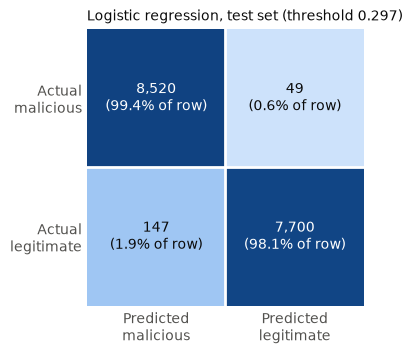

In [14]:
cm = confusion_matrix(y_test, pred_a, labels=[1, 0])   # rows/cols: malicious first
seq_blue = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#2a78d6", "#104281"])

fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.imshow(cm, cmap=seq_blue, norm=LogNorm(vmin=cm.min(), vmax=cm.max()))
names = ["Malicious", "Legitimate"]
for i in range(2):
    for j in range(2):
        share = cm[i, j] / cm[i].sum()
        dark_cell = cm[i, j] > 1000
        ax.text(j, i, f"{cm[i, j]:,}\n({share:.1%} of row)", ha="center", va="center",
                fontsize=10, color="#ffffff" if dark_cell else INK)
ax.set_xticks([0, 1], [f"Predicted\n{n.lower()}" for n in names])
ax.set_yticks([0, 1], [f"Actual\n{n.lower()}" for n in names])
ax.tick_params(which="both", length=0, labelcolor=INK_2)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xticks([0.5], minor=True); ax.set_yticks([0.5], minor=True)
ax.grid(which="minor", color="#ffffff", linewidth=2)   # 2px surface gap between cells
ax.set_title(f"Logistic regression, test set (threshold {threshold_a:.3f})", fontsize=10, loc="left")
save(fig, "confusion_matrix_A")
plt.show()

### 8.2 Precision-recall curve
Each point is one possible threshold. Axes are zoomed: the full curve hugs the top-right corner.

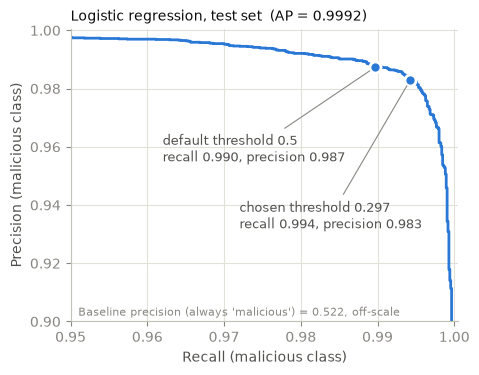

In [15]:
prec_t, rec_t, thr_t = precision_recall_curve(y_test, test_proba_a, pos_label=1)
fig, ax = plt.subplots(figsize=(5, 3.8))
ax.plot(rec_t, prec_t, color=BLUE, linewidth=2)
# Labels sit in the empty lower-left area, joined to their point by a thin leader line.
for t, label, text_xy in [(0.5, "default threshold 0.5", (0.962, 0.955)),
                          (threshold_a, f"chosen threshold {threshold_a:.3f}", (0.972, 0.932))]:
    p = (test_proba_a >= t).astype(int)
    r_, p_ = recall_score(y_test, p), precision_score(y_test, p)
    ax.plot(r_, p_, "o", markersize=8, color=BLUE, markeredgecolor="#ffffff", markeredgewidth=2, zorder=3)
    ax.annotate(f"{label}\nrecall {r_:.3f}, precision {p_:.3f}", (r_, p_), xytext=text_xy,
                ha="left", fontsize=9, color=INK_2,
                arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8, shrinkB=5))
ax.set_xlim(0.95, 1.0005); ax.set_ylim(0.90, 1.0005)
ax.set_xlabel("Recall (malicious class)"); ax.set_ylabel("Precision (malicious class)")
ax.grid(color=GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.set_title(f"Logistic regression, test set  (AP = {average_precision_score(y_test, test_proba_a):.4f})",
             fontsize=10, loc="left")
ax.text(0.951, 0.902, f"Baseline precision (always 'malicious') = {y_test.mean():.3f}, off-scale",
        fontsize=8, color=MUTED)
save(fig, "precision_recall_A")
plt.show()

## 9. Interpretability: learned weights θ
Positive weight -> the term pushes an email towards **malicious**; negative -> towards **legitimate**.
Weights come from the final model (fitted on train + validation).

In [16]:
terms = model_a.named_steps["tfidf"].get_feature_names_out()
theta = model_a.named_steps["lr"].coef_.ravel()
order = np.argsort(theta)
top_pos = pd.DataFrame({"term": terms[order[::-1][:20]], "weight": theta[order[::-1][:20]]})
top_neg = pd.DataFrame({"term": terms[order[:20]], "weight": theta[order[:20]]})
weights_table = pd.concat([top_pos.add_suffix(" (malicious)"), top_neg.add_suffix(" (legitimate)")], axis=1)
weights_table.index = range(1, 21)
weights_table.to_csv(RESULTS_DIR / "top_weights_A.csv")
print(weights_table.to_string(float_format="%.2f"))

   term (malicious)  weight (malicious) term (legitimate)  weight (legitimate)
1              2004               23.50             enron               -38.15
2     josemonkeyorg               23.20             wrote               -32.21
3           replica               20.53                pm               -22.85
4              2017               18.42            ierant               -21.33
5              2016               16.49             vince               -20.09
6              0300               15.17          opensuse               -18.88
7              2019               14.02            louise               -18.27
8              http               13.85        university               -17.86
9              2018               13.75            thanks               -17.74
10          watches               13.50              tony               -17.15
11             2005               13.29              1300               -17.13
12           top 10               13.29             

## 10. Failure analysis: false negatives of model A
The 5 malicious test emails that received the **lowest** probability of being malicious,
i.e. the phishing/spam the model was most confident was safe.
Note: the dataset text is pre-processed (lower-cased, stop words and punctuation removed).

In [17]:
fn_mask = (y_test.to_numpy() == 1) & (pred_a == 0)
fn = pd.DataFrame({"p_malicious": test_proba_a[fn_mask], "text": X_test.to_numpy()[fn_mask]})
fn = fn.sort_values("p_malicious").reset_index(drop=True)
print(f"False negatives: {len(fn)} of {int(y_test.sum())} malicious test emails\n")
fn.to_csv(RESULTS_DIR / "false_negatives_A.csv", index=False)
for i, row in fn.head(5).iterrows():
    print(f"[{i + 1}] p(malicious) = {row.p_malicious:.4f}   ({len(row.text.split())} words)")
    print("    " + row.text[:400] + ("..." if len(row.text) > 400 else ""), "\n")

False negatives: 49 of 8569 malicious test emails

[1] p(malicious) = 0.0000   (65 words)
    david farber davefarbernet begin forwarded message tony rajakumar date december 4 2006 24759 pm est david farber subject vanishing clickfraud case replyto arajakumcomputerorg dave ip wish arrested clickfraudster claimed make 30k month via google clickfraud freed possible lack cooperation google httpyahoobusinessweekcomtechnologycontentdec2006 tc20061204_923336htm tony rajakumar victrio inc tonyrvi... 

[2] p(malicious) = 0.0012   (9 words)
    google yahoo cade etc caso consiga visualizar clique aqui 

[3] p(malicious) = 0.0034   (127 words)
    90 l 50 cost effective solutions global translations 0018457 190 64477507020 37615090 37615091 1 90 120 160 180 220 240 400 280 500 360 600 140 180 200 240 280 440 320 540 400 640 180 220 240 280 320 480 360 580 440 680 400 8 600 8 l 000 8 dear international manager company based beijing china providing high translation services world commercially sign

## 11. Does the model learn the *style of each corpus*?
`phishing_email.csv` merges six corpora but has no column saying where each email comes from.
Two of them (Nazario, Nigerian Fraud) contain **only** malicious emails, and Enron is mostly
business email, so a model could learn "sounds like Enron = safe" instead of real phishing cues.

### 11.1 Recover the source corpus of each email
The per-corpus CSVs of the same Kaggle download contain the original subject + body. The combined
text was pre-processed (lower-cased, punctuation, stop words and non-ASCII characters removed),
so we cannot match strings exactly. Instead we compare **sets of long words** (≥ 6 letters,
never stop words): each email is assigned to the corpus row with the same label and the highest
Jaccard similarity, if that similarity is ≥ 0.5. Otherwise its source is `unknown`.

In [18]:
SOURCES = ["CEAS_08", "Enron", "Ling", "Nazario", "Nigerian_Fraud", "SpamAssasin"]


def long_words(text):
    text = text.encode("ascii", "ignore").decode().lower()
    return frozenset(w for w in re.findall(r"[a-z]+", text) if len(w) >= 6)


src_rows = []   # (corpus, label, word set)
for name in SOURCES:
    part = pd.read_csv(DATA_PATH.parent / f"{name}.csv", usecols=["subject", "body", "label"])
    text = part["subject"].fillna("").astype(str) + " " + part["body"].fillna("").astype(str)
    src_rows += [(name, lab, long_words(t)) for t, lab in zip(text, part["label"])]

doc_freq = Counter(w for _, _, ws in src_rows for w in ws)
index = defaultdict(list)          # rare word -> source rows containing it
for i, (_, _, ws) in enumerate(src_rows):
    for w in sorted(ws, key=doc_freq.__getitem__)[:3]:
        index[w].append(i)


def match_source(text, label):
    ws = long_words(text)
    candidates = {i for w in sorted(ws, key=lambda w: doc_freq.get(w) or 10**9)[:5] for i in index.get(w, [])}
    best, best_sim = "unknown", 0.5
    for i in candidates:
        name, lab, src_ws = src_rows[i]
        if lab == label and src_ws:
            sim = len(ws & src_ws) / len(ws | src_ws)
            if sim >= best_sim:
                best, best_sim = name, sim
    return best


df["source"] = [match_source(t, l) for t, l in zip(df["text_combined"], df["label"])]
source_counts = (df.groupby("source")["label"].agg(emails="size", malicious_share="mean")
                 .sort_values("emails", ascending=False))
print(source_counts.to_string(float_format="%.3f"))
print(f"\nSource recovered for {(df['source'] != 'unknown').mean():.1%} of the emails")

                emails  malicious_share
source                                 
CEAS_08          33195            0.532
Enron            29576            0.479
unknown           6888            0.668
SpamAssasin       4928            0.266
Nigerian_Fraud    3283            1.000
Ling              2852            0.160
Nazario           1355            1.000

Source recovered for 91.6% of the emails


### 11.2 Per-corpus results of model A on the test set
Same final model and threshold as above; the test set is only split by source.

In [19]:
source_test = df.loc[X_test.index, "source"].to_numpy()


def corpus_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    has_legit = (y_true == 0).any()
    return {
        "emails": len(y_true),
        "malicious_share": y_true.mean(),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "precision": precision_score(y_true, y_pred, zero_division=0) if has_legit else np.nan,
        "f1": f1_score(y_true, y_pred, zero_division=0) if has_legit else np.nan,
        "FN": int(((y_true == 1) & (y_pred == 0)).sum()),
        "FP": int(((y_true == 0) & (y_pred == 1)).sum()),
    }


per_corpus = pd.DataFrame({
    s: corpus_metrics(y_test[source_test == s], pred_a[source_test == s])
    for s in SOURCES + ["unknown"]
}).T
print(per_corpus.to_string(float_format="%.4f"))
print("\nprecision / F1 are undefined (NaN) for corpora with no legitimate emails.")

                  emails  malicious_share  recall  precision     f1      FN      FP
CEAS_08        6521.0000           0.5329  0.9994     0.9850 0.9921  2.0000 53.0000
Enron          5988.0000           0.4785  0.9878     0.9803 0.9840 35.0000 57.0000
Ling            567.0000           0.1481  0.9762     0.8817 0.9266  2.0000 11.0000
Nazario         296.0000           1.0000  0.9899        NaN    NaN  3.0000  0.0000
Nigerian_Fraud  665.0000           1.0000  1.0000        NaN    NaN  0.0000  0.0000
SpamAssasin     981.0000           0.2681  0.9886     0.9420 0.9647  3.0000 16.0000
unknown        1398.0000           0.6588  0.9957     0.9892 0.9924  4.0000 10.0000

precision / F1 are undefined (NaN) for corpora with no legitimate emails.


### 11.3 Leave-one-corpus-out (LOCO)
For each corpus K: train model A (same C, same threshold) on **all other corpora**, then evaluate on
**all emails of K**. If the model had learned general phishing cues, performance on an unseen
corpus would stay close to the in-distribution result of 11.2. A large drop means the model
relied on corpus-specific style. Emails with `unknown` source are excluded from both sides, so
that no email of the held-out corpus can leak into training.

In [20]:
known = df[df["source"] != "unknown"]
loco_rows = []
for held_out in SOURCES:
    train_part, test_part = known[known["source"] != held_out], known[known["source"] == held_out]
    loco_model = Pipeline([
        ("tfidf", TfidfVectorizer(**TFIDF_PARAMS)),
        ("lr", LogisticRegression(C=best_C, l1_ratio=0.0, max_iter=1000, random_state=RANDOM_STATE)),
    ]).fit(train_part["text_combined"], train_part["label"])
    loco_pred = (loco_model.predict_proba(test_part["text_combined"])[:, 1] >= threshold_a).astype(int)
    m = corpus_metrics(test_part["label"], loco_pred)
    loco_rows.append({"held_out": held_out, "emails": m["emails"],
                      "recall_in_dist": per_corpus.loc[held_out, "recall"], "recall_LOCO": m["recall"],
                      "f1_in_dist": per_corpus.loc[held_out, "f1"], "f1_LOCO": m["f1"],
                      "FN_LOCO": m["FN"], "FP_LOCO": m["FP"]})
    print(f"done: {held_out}")

loco = pd.DataFrame(loco_rows)
loco.to_csv(RESULTS_DIR / "leave_one_corpus_out.csv", index=False)
per_corpus.to_csv(RESULTS_DIR / "per_corpus_test_A.csv")
print()
print(loco.to_string(index=False, float_format="%.4f"))

done: CEAS_08


done: Enron


done: Ling


done: Nazario


done: Nigerian_Fraud


done: SpamAssasin

      held_out  emails  recall_in_dist  recall_LOCO  f1_in_dist  f1_LOCO  FN_LOCO  FP_LOCO
       CEAS_08   33195          0.9994       0.9281      0.9921   0.8836     1271     3049
         Enron   29576          0.9878       0.9026      0.9840   0.7941     1380     5249
          Ling    2852          0.9762       0.9605      0.9266   0.7204       18      322
       Nazario    1355          0.9899       0.6745         NaN      NaN      441        0
Nigerian_Fraud    3283          1.0000       0.9933         NaN      NaN       22        0
   SpamAssasin    4928          0.9886       0.9878      0.9647   0.7220       16      983
